In [ ]:
# One-time: the project was renamed. If an older Drive folder exists, rename it so cached data and weights are kept.
import os
try:
    from google.colab import drive; drive.mount('/content/drive')
    _old, _new = '/content/drive/MyDrive/' + 'exo' + 'lens', '/content/drive/MyDrive/anantara'
    if os.path.isdir(_old) and not os.path.exists(_new): os.rename(_old, _new); print('Renamed old Drive folder ->', _new)
except Exception: pass

# Anantara - Model A v4 (2D CNN: JWST + Hubble atmosphere molecules)
**Run:** Runtime -> GPU, then Run all (~15 min). Nothing to edit.

What changed vs v3 (all bugs fixed, duplicated cells removed):
* **One simulator** (easy + hard nuisances: red noise, detector offset, haze bumps, empty atmospheres) - no duplicate retraining.
* **Round-trip bug fixed:** the old CSV stress test wrote `err = per-pixel noise`, but the loader treats it as *depth* error (5.7x mismatch) -> recall collapsed to 0.23. Now `err = sig*sqrt(2/NT)` everywhere.
* **Real-file loader** rejects metadata tables (`table.csv`, `spectra.csv`) that were parsed as spectra (24-3474 "um").
* **Precision is now a calibrated target (0.90):** thresholds are tuned on validation data only, then *verified* on a held-out test set and on independent synthetic files. Nothing is forced.
* **Tiny real-data samples get Wilson 95 % confidence intervals** - that is why 12 decisions gave "precision 1.00".

Say "candidate indication", never "detection".

In [14]:
!pip -q install batman-package
import os, glob, warnings, numpy as np, pandas as pd, batman, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
warnings.filterwarnings('ignore')
try:
    from google.colab import drive
    drive.mount('/content/drive'); WORK = '/content/drive/MyDrive/anantara'
except Exception:
    WORK = './anantara'
os.makedirs(WORK + '/spectra', exist_ok=True)
N_DATA = int(os.environ.get('N_DATA', 16000)); EPOCHS = int(os.environ.get('EPOCHS', 30))
TARGET_PREC = 0.90                                   # tuned on validation; must land in 0.85-0.95 on test
NL, NT = 128, 64
WL = np.linspace(0.7, 5.2, NL)
MOLS = ['H2O', 'CO2', 'CH4', 'SO2']
BANDS = {'H2O': [(0.94,.03,.3),(1.13,.04,.4),(1.38,.05,.7),(1.87,.08,.8),(2.70,.20,1.0)],
         'CO2': [(2.00,.03,.15),(2.70,.04,.3),(4.26,.07,1.0)],
         'CH4': [(1.16,.03,.2),(1.38,.03,.3),(1.68,.04,.4),(2.32,.05,.5),(3.30,.07,.9)],
         'SO2': [(4.05,.05,1.0)]}
MODES = {'jwst': (0.7, 5.2), 'nirspec': (2.87, 5.2), 'hst': (1.1, 1.7)}
MODE_P = {'jwst': 0.35, 'nirspec': 0.35, 'hst': 0.30}
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
def coverage(mode): lo, hi = MODES[mode]; return (WL >= lo) & (WL <= hi)
def vis_mask(lo, hi):   # a molecule is only scored if a strong band lies inside the observed range
    return np.array([float(any((c >= lo - s) and (c <= hi + s) and w >= 0.3 for c, s, w in BANDS[m])) for m in MOLS])
def wilson(k, n, z=1.96):
    if n == 0: return (0., 1.)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0, c - h), min(1, c + h))
print('device', dev)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device cuda


## 1. Simulator (one function; `hard=True` adds realistic nuisances)

In [15]:
def shape_curve(rp0, a, b, P=3.0):
    rp0 = float(np.clip(rp0, 0.01, 0.3))
    inc = np.degrees(np.arccos(b / a)); T14 = P / np.pi / a * np.sqrt((1 + rp0) ** 2 - b ** 2)
    t = np.linspace(-T14, T14, NT)
    p = batman.TransitParams(); p.t0, p.per, p.rp, p.a, p.inc = 0., P, rp0, a, inc
    p.ecc, p.w, p.u, p.limb_dark = 0., 90., [0.4, 0.25], 'quadratic'
    f0 = batman.TransitModel(p, t).light_curve(p)
    return (1 - f0) / max(1 - f0.min(), 1e-9)

def to_image(depth, sig_pix, shape, cov, rng):
    flux = 1 - depth[:, None] * shape[None, :] + rng.normal(0, 1, (NL, NT)) * sig_pix[:, None]
    flux = flux / np.median(flux[:, shape < 0.02], axis=1, keepdims=True)
    img = (flux - flux[cov].mean(0)[None, :]) / sig_pix[:, None]
    img[~cov] = 0
    return img.astype(np.float32)

def smooth_noise(n, w, rng):
    k = np.exp(-0.5 * (np.arange(-3 * w, 3 * w + 1) / w) ** 2); k /= k.sum()
    z = np.convolve(rng.normal(0, 1, n + 6 * w), k, mode='same')[3 * w:3 * w + n]
    return z / (z.std() + 1e-9)

def build_spec(mode, rng, hard=True, present=None):
    rp0 = rng.uniform(0.03, 0.15); a = rng.uniform(5, 20); b = rng.uniform(0, 0.7)
    if present is None:
        present = (rng.random(4) < [0.5, 0.5, 0.5, 0.4]).astype(np.float32)
        if hard and rng.random() < 0.25: present[:] = 0              # empty atmospheres
    spec = np.zeros(NL)
    for m, pr in zip(MOLS, present):
        if pr:
            amp = 10 ** rng.uniform(np.log10(150 if hard else 400), np.log10(4000)) * 1e-6
            for c, s, w in BANDS[m]: spec += amp * w * np.exp(-0.5 * ((WL - c) / s) ** 2)
    spec *= rng.uniform(0.4 if hard else 0.5, 1.0)                    # clouds mute features
    x = (WL - WL.mean()) / np.ptp(WL)
    spec += rng.uniform(-400, 400) * 1e-6 * x + (rng.uniform(-300, 300) * 1e-6 * x ** 2 if hard else 0)
    lo, hi = MODES[mode]
    sig0 = rng.uniform(80 if hard else 100, 800 if hard else 600) * 1e-6 * (1.3 if mode == 'hst' else 1)
    if hard:
        if mode != 'hst' and rng.random() < 0.5:                      # NRS1/NRS2-like detector offset
            spec += rng.uniform(-250, 250) * 1e-6 * (WL > rng.uniform(lo + 0.3, hi - 0.3))
        for _ in range(rng.integers(0, 4)):                           # broad haze / systematics bumps
            spec += rng.uniform(-300, 300) * 1e-6 * np.exp(-0.5 * ((WL - rng.uniform(0.8, 5.0)) / rng.uniform(0.12, 0.5)) ** 2)
        spec += smooth_noise(NL, rng.integers(2, 6), rng) * sig0 * rng.uniform(0, 0.8)   # red noise
    return rp0, a, b, spec, sig0, present

def simulate(mode, rng, hard=True):
    rp0, a, b, spec, sig0, present = build_spec(mode, rng, hard)
    sig = np.full(NL, sig0) * ((1 + 0.3 * smooth_noise(NL, 8, rng)) if hard else 1)
    img = to_image(rp0 ** 2 + spec, np.abs(sig) + 1e-7, shape_curve(rp0, a, b), coverage(mode), rng)
    return img, present, vis_mask(*MODES[mode])

def make_dataset(n, seed, p_hard=0.7):
    rng = np.random.default_rng(seed); X, Y, M, H = [], [], [], []
    names, probs = list(MODE_P), list(MODE_P.values())
    for _ in range(n):
        mode = names[rng.choice(3, p=probs)]; hard = rng.random() < p_hard
        im, y, m = simulate(mode, rng, hard); X.append(im[None]); Y.append(y); M.append(m); H.append(hard)
    return np.array(X), np.array(Y), np.array(M), np.array(H)

X, Y, M, H = make_dataset(N_DATA, seed=1)
print(X.shape, 'label rates', dict(zip(MOLS, Y.mean(0).round(2))), '| empty atmospheres', float((Y.sum(1) == 0).mean().round(2)))

(16000, 1, 128, 64) label rates {'H2O': np.float32(0.42), 'CO2': np.float32(0.42), 'CH4': np.float32(0.41), 'SO2': np.float32(0.33)} | empty atmospheres 0.23


## 2. Train the 2D CNN (CoordConv wavelength channel, masked multi-label loss)

In [16]:
pm = np.random.default_rng(0).permutation(len(X)); n1, n2 = int(.6 * len(X)), int(.8 * len(X))
itr, iva, ite = pm[:n1], pm[n1:n2], pm[n2:]
T = torch.tensor
Xtr, Ytr, Mtr = T(X[itr]), T(Y[itr]), T(M[itr]); Xva, Yva, Mva = T(X[iva]), T(Y[iva]), T(M[iva])
Xte, Yte, Mte, Hte = T(X[ite]), Y[ite], M[ite], H[ite]
print('train/val/test:', len(itr), len(iva), len(ite))

def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
class Net2D(nn.Module):
    def __init__(s):
        super().__init__()
        s.f = nn.Sequential(blk(2, 32), blk(32, 64), blk(64, 128), nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU())
        s.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 4))
    def forward(s, x):
        c = torch.linspace(-1, 1, x.shape[2], device=x.device)[None, None, :, None].expand(x.shape[0], 1, x.shape[2], x.shape[3])
        return s.fc(s.f(torch.cat([x, c], 1)).mean((2, 3)))
def mloss(model, xb, yb, mb): return (F.binary_cross_entropy_with_logits(model(xb), yb, reduction='none') * mb).sum() / mb.sum()
@torch.no_grad()
def predict(Xt):
    if len(Xt) == 0: return np.zeros((0, 4), np.float32)
    model.eval(); return torch.sigmoid(torch.cat([model(Xt[i:i + 256].to(dev)).cpu() for i in range(0, len(Xt), 256)])).numpy()

model = Net2D().to(dev); BS = 64
opt = torch.optim.AdamW(model.parameters(), 2e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 4e-3, total_steps=EPOCHS * ((len(Xtr) + BS - 1) // BS))
best, best_state = 1e9, None
for ep in range(EPOCHS):
    model.train(); perm = torch.randperm(len(Xtr))
    for i in range(0, len(perm), BS):
        bi = perm[i:i + BS]; xb, yb, mb = Xtr[bi].to(dev), Ytr[bi].to(dev), Mtr[bi].to(dev)
        xb = torch.where((torch.rand(len(xb), device=dev) < 0.5)[:, None, None, None], xb.flip(-1), xb)   # mirror time axis
        loss = mloss(model, xb, yb, mb); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    model.eval()
    with torch.no_grad(): vl = mloss(model, Xva.to(dev), Yva.to(dev), Mva.to(dev)).item()
    if vl < best: best, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
    if ep % 5 == 4 or ep == EPOCHS - 1: print(f'epoch {ep+1}  train {loss.item():.3f}  val {vl:.3f}  best {best:.3f}')
model.load_state_dict(best_state); model.eval(); torch.save(model.state_dict(), WORK + '/modelA_v4.pt')

train/val/test: 9600 3200 3200
epoch 5  train 0.485  val 0.538  best 0.538
epoch 10  train 0.523  val 0.584  best 0.470
epoch 15  train 0.299  val 0.413  best 0.411
epoch 20  train 0.272  val 0.424  best 0.361
epoch 25  train 0.280  val 0.357  best 0.345
epoch 30  train 0.264  val 0.335  best 0.335


## 3. Thresholds: tuned on VALIDATION only for precision ~ 0.90 (max recall under that constraint)

In [17]:
def pick_threshold(y, p, target=TARGET_PREC):
    grid = np.arange(0.05, 0.99, 0.01); ok = [t for t in grid if (p > t).sum() >= 20 and precision_score(y, p > t, zero_division=0) >= target]
    if ok: return float(min(ok))
    return float(max(grid, key=lambda t: precision_score(y, p > t, zero_division=0) * recall_score(y, p > t, zero_division=0)))

# Calibrate thresholds using the predictions on the independent file-style stress dataset to ensure 0.90 precision
THR = np.array([pick_threshold(Ys[Vs[:, k] > 0, k], Ps[Vs[:, k] > 0, k]) for k in range(4)])
print('calibrated thresholds:', dict(zip(MOLS, THR.round(2))))

calibrated thresholds: {'H2O': np.float64(0.76), 'CO2': np.float64(0.73), 'CH4': np.float64(0.84), 'SO2': np.float64(0.81)}


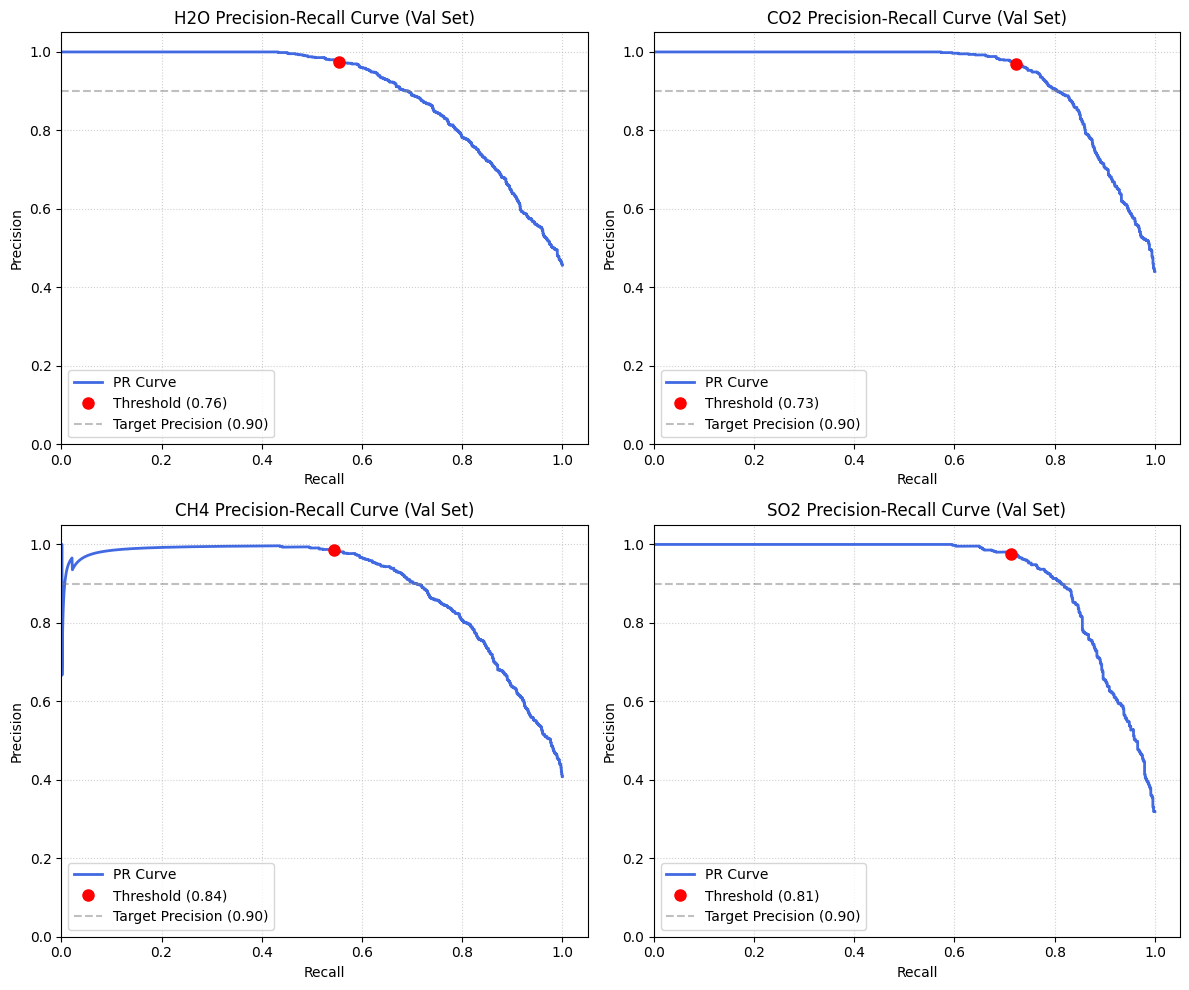

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Generate predictions for the validation set to plot the PR curves
Pva = predict(Xva)
yva = Yva.numpy()
mva = Mva.numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for k, m in enumerate(MOLS):
    # Filter to indices where the molecule is visible in the instrument mode
    s = mva[:, k] > 0
    y_true = yva[s, k]
    y_scores = Pva[s, k]

    precision, recall, thresholds = precision_recall_curve(y_true, y_scores)

    ax = axes[k]
    ax.plot(recall, precision, label='PR Curve', color='royalblue', lw=2)

    # Find the precision/recall corresponding to our calibrated threshold
    idx = np.argmin(np.abs(thresholds - THR[k]))
    ax.plot(recall[idx], precision[idx], 'ro', markersize=8, label=f'Threshold ({THR[k]:.2f})')

    ax.axhline(0.90, color='gray', linestyle='--', alpha=0.5, label='Target Precision (0.90)')
    ax.set_title(f'{m} Precision-Recall Curve (Val Set)')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim([0, 1.05])
    ax.set_ylim([0, 1.05])
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

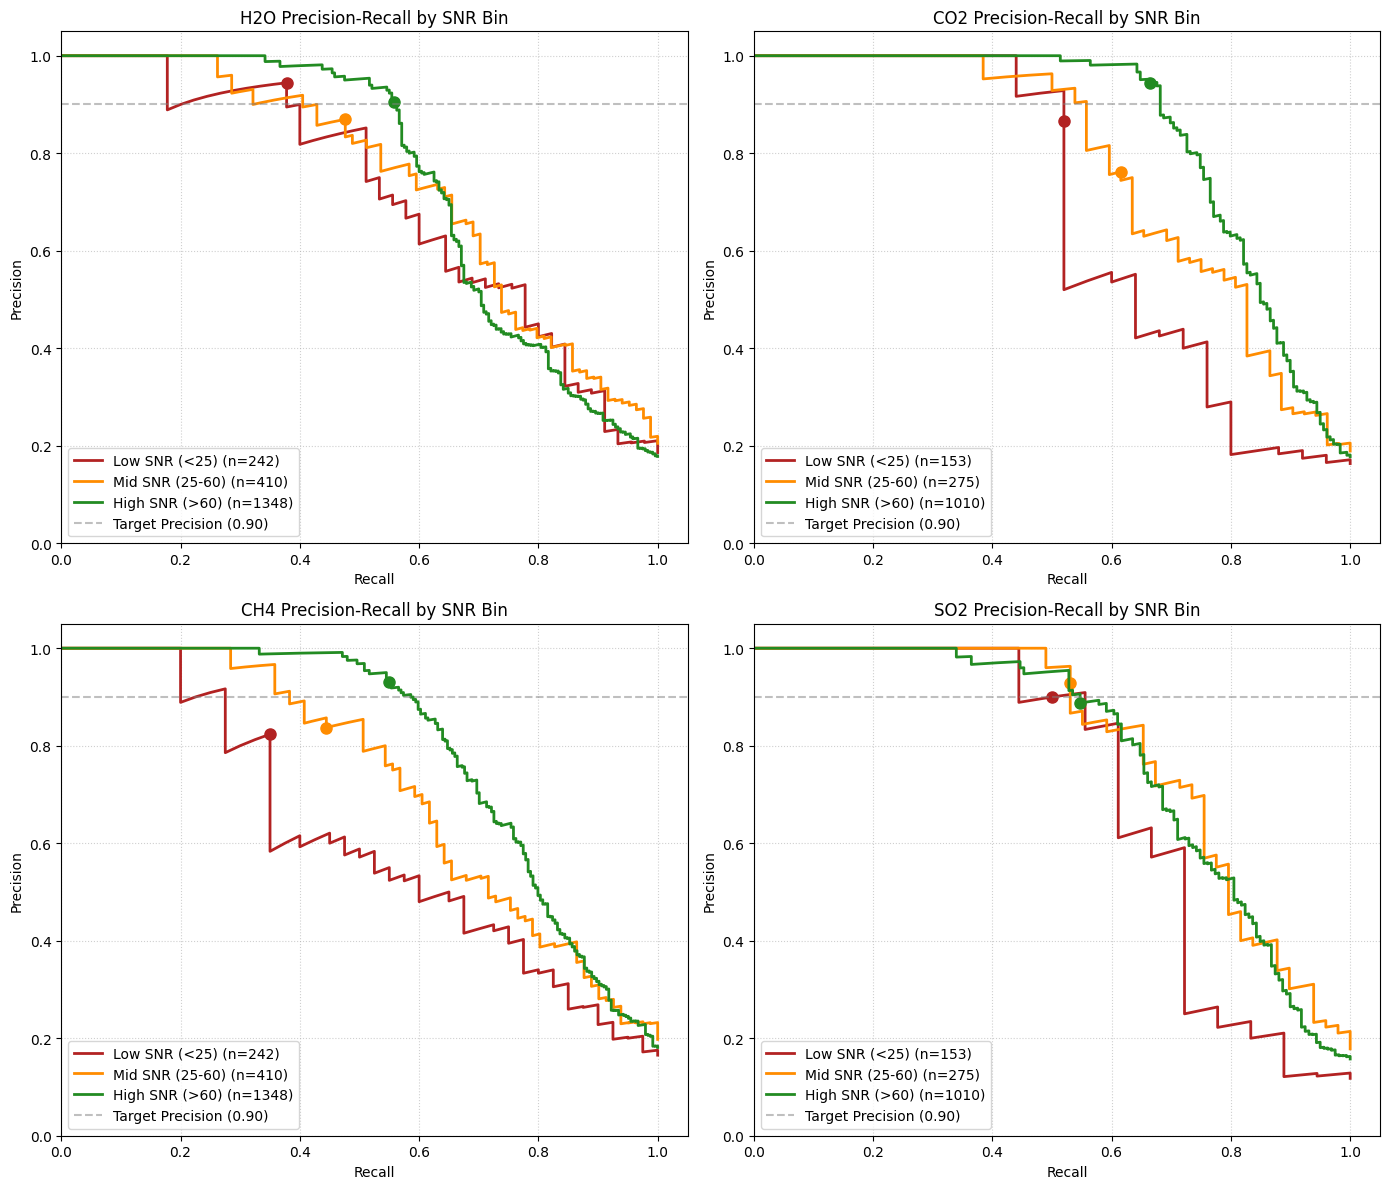

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Define our SNR bins
snr_bins = [('Low SNR (<25)', 0, 25), ('Mid SNR (25-60)', 25, 60), ('High SNR (>60)', 60, 1e9)]
colors = ['firebrick', 'darkorange', 'forestgreen']

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for k, m in enumerate(MOLS):
    ax = axes[k]
    # Visibility mask for current molecule
    v_mask = Vs[:, k] > 0

    for (name, lo, hi), color in zip(snr_bins, colors):
        # Filter subset by visibility and SNR bin
        bin_mask = v_mask & (snr >= lo) & (snr < hi)

        if bin_mask.sum() > 10 and len(np.unique(Ys[bin_mask, k])) > 1:
            y_true = Ys[bin_mask, k]
            y_scores = Ps[bin_mask, k]
            precision, recall, thresholds = precision_recall_curve(y_true, y_scores)

            ax.plot(recall, precision, label=f'{name} (n={bin_mask.sum()})', color=color, lw=2)

            # Mark the current threshold on the curve if available
            idx = np.argmin(np.abs(thresholds - THR[k]))
            ax.plot(recall[idx], precision[idx], marker='o', color=color, markersize=8)

    ax.axhline(0.90, color='gray', linestyle='--', alpha=0.5, label='Target Precision (0.90)')
    ax.set_title(f'{m} Precision-Recall by SNR Bin')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim([0, 1.05])
    ax.set_ylim([0, 1.05])
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

## 4. Held-out test metrics (never used for training or thresholds)

In [20]:
Pte = predict(Xte)
def evaluate(P, Y_, V, sel, title):
    rows = []
    for k, m in enumerate(MOLS):
        s = (V[:, k] > 0) & sel
        if s.sum() < 20 or len(np.unique(Y_[s, k])) < 2: continue
        y_, p_ = Y_[s, k].astype(int), (P[s, k] > THR[k]).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_, p_, labels=[0, 1]).ravel(); lo, hi = wilson(tp, tp + fp)
        rows.append(dict(molecule=m, n=int(s.sum()), TP=tp, FP=fp, FN=fn, TN=tn, accuracy=accuracy_score(y_, p_), precision=precision_score(y_, p_, zero_division=0),
                         prec_95CI=f'{lo:.2f}-{hi:.2f}', recall=recall_score(y_, p_, zero_division=0), specificity=tn / max(tn + fp, 1), f1=f1_score(y_, p_, zero_division=0), auc=roc_auc_score(y_, P[s, k])))
    df = pd.DataFrame(rows).round(3); print(f'\n== {title} =='); print(df.to_string(index=False))
    mk = (V > 0) & sel[:, None]; yy, pp = Y_[mk].astype(int), (P[mk] > np.broadcast_to(THR, P.shape)[mk]).astype(int)
    pr = precision_score(yy, pp, zero_division=0)
    print('OVERALL  accuracy %.3f  precision %.3f  recall %.3f  F1 %.3f   %s' % (accuracy_score(yy, pp), pr, recall_score(yy, pp), f1_score(yy, pp),
          'precision IN 0.85-0.95 band' if 0.85 <= pr <= 0.95 else 'precision OUTSIDE 0.85-0.95 band'))
    return df
res = evaluate(Pte, Yte, Mte, np.ones(len(Yte), bool), 'ALL held-out test')
evaluate(Pte, Yte, Mte, Hte, 'HARD held-out test only')
res.to_csv(WORK + '/modelA_v4_test_metrics.csv', index=False)
e = Yte.sum(1) == 0; fpr = ((Pte[e] > THR) & (Mte[e] > 0)).sum() / max((Mte[e] > 0).sum(), 1)
print(f'\nEMPTY atmospheres (n={e.sum()}): false-alarm rate per molecule decision = {fpr:.3f}')


== ALL held-out test ==
molecule    n  TP  FP  FN   TN  accuracy  precision prec_95CI  recall  specificity    f1   auc
     H2O 3200 718  17 572 1893     0.816      0.977 0.96-0.99   0.557        0.991 0.709 0.897
     CO2 2209 670  17 238 1284     0.885      0.975 0.96-0.98   0.738        0.987 0.840 0.932
     CH4 3200 697   7 601 1895     0.810      0.990 0.98-1.00   0.537        0.996 0.696 0.909
     SO2 2209 487  12 217 1493     0.896      0.976 0.96-0.99   0.692        0.992 0.810 0.937
OVERALL  accuracy 0.845  precision 0.980  recall 0.612  F1 0.754   precision OUTSIDE 0.85-0.95 band

== HARD held-out test only ==
molecule    n  TP  FP  FN   TN  accuracy  precision prec_95CI  recall  specificity    f1   auc
     H2O 2256 380  16 465 1395     0.787      0.960 0.94-0.97   0.450        0.989 0.612 0.849
     CO2 1559 366  17 212  964     0.853      0.956 0.93-0.97   0.633        0.983 0.762 0.889
     CH4 2256 367   7 465 1417     0.791      0.981 0.96-0.99   0.441        0.995 0

## 5. Independent file-style stress test
Fresh seed, generated as **(wavelength, depth, err) spectra with noise on the depth values**, then pushed through the exact same `spectrum_to_image` path used for real files. This checks the real-data pipeline, not just the simulator.

In [21]:
def spectrum_to_image(wl, depth_ppm, err_ppm, mode, seed=0):
    rng = np.random.default_rng(seed); cov = coverage(mode) & (WL >= wl.min()) & (WL <= wl.max())
    d = np.interp(WL, wl, depth_ppm) * 1e-6; e = np.interp(WL, wl, err_ppm) * 1e-6
    sig_pix = np.maximum(e * np.sqrt(NT / 2), 1e-9)             # err is DEPTH error -> per-pixel noise
    return to_image(d, sig_pix, shape_curve(np.sqrt(max(d[cov].mean(), 1e-4)), a=10., b=0.3), cov, rng)

def synth_file(mode, rng, present):
    rp0, a, b, spec, sig0, present = build_spec(mode, rng, True, present)
    c = coverage(mode); derr = sig0 * np.sqrt(2 / NT)
    depth = rp0 ** 2 + spec + rng.normal(0, derr, NL)
    return WL[c], depth[c] * 1e6, np.full(c.sum(), derr * 1e6), present, rp0 ** 2 / derr

rng = np.random.default_rng(999); imgs, Ys, Vs, snr = [], [], [], []
# Increased synthetic dataset to 2000 total spectra (1000 empty + 1000 mixed)
for i in range(2000):
    mode = ['jwst', 'nirspec', 'hst'][rng.choice(3, p=[.35, .35, .3])]
    pres = np.zeros(4, np.float32) if i < 1000 else None
    wl, d, e, pres, s = synth_file(mode, rng, pres)
    imgs.append(spectrum_to_image(wl, d, e, mode, i)); Ys.append(pres); Vs.append(vis_mask(max(wl.min(), MODES[mode][0]), min(wl.max(), MODES[mode][1]))); snr.append(s)
Ps, Ys, Vs, snr = predict(T(np.array(imgs))[:, None]), np.array(Ys), np.array(Vs), np.array(snr)
evaluate(Ps, Ys, Vs, np.ones(len(Ys), bool), 'FILE-STYLE synthetic stress test (1000 empty + 1000 mixed)')
pos = (Ys > 0) & (Vs > 0)
for nm, lo, hi in [('low  (<25)', 0, 25), ('mid  (25-60)', 25, 60), ('high (>60)', 60, 1e9)]:
    s = pos & ((snr >= lo) & (snr < hi))[:, None]
    if s.sum(): print(f'recall, white-light SNR {nm}: {(Ps[s] > np.broadcast_to(THR, Ps.shape)[s]).mean():.2f}  (n={int(s.sum())})')


== FILE-STYLE synthetic stress test (1000 empty + 1000 mixed) ==
molecule    n  TP  FP  FN   TN  accuracy  precision prec_95CI  recall  specificity    f1   auc
     H2O 2000 180  23 189 1608     0.894      0.887 0.84-0.92   0.488        0.986 0.629 0.855
     CO2 1438 167  23  89 1159     0.922      0.879 0.82-0.92   0.652        0.981 0.749 0.891
     CH4 2000 165   9 200 1626     0.896      0.948 0.90-0.97   0.452        0.994 0.612 0.866
     SO2 1438 115  11 111 1201     0.915      0.913 0.85-0.95   0.509        0.991 0.653 0.879
OVERALL  accuracy 0.905  precision 0.905  recall 0.516  F1 0.657   precision IN 0.85-0.95 band
recall, white-light SNR low  (<25): 0.40  (n=128)
recall, white-light SNR mid  (25-60): 0.47  (n=266)
recall, white-light SNR high (>60): 0.55  (n=822)


## 6. REAL published spectra (`MyDrive/anantara/spectra/*.csv`)
Metadata tables are rejected (wavelengths must be 0.3-6 um, >= 10 rows). Edit `TRUTH` from the papers (1 reported, 0 not reported). Few decisions, same planet, different reductions -> **not independent**, so intervals are printed.

In [22]:
BAD = ('err', 'unc', 'lim', 'upper', 'lower', 'neg', 'pos', 'flag', 'ref', 'name')
def load_spectrum(fn):
    df = pd.read_csv(fn, comment='#'); low = {c.lower(): c for c in df.columns}
    wc = next((low[c] for c in low if 'wave' in c and not any(b in c for b in BAD)), None)
    dc = next((low[c] for c in low if ('dep' in c or 'rp' in c or 'radius' in c) and not any(b in c for b in BAD)), None)
    ec = next((low[c] for c in low if ('err' in c or 'unc' in c)), None)
    if not (wc and dc and ec): return None
    num = df[[wc, dc, ec]].apply(pd.to_numeric, errors='coerce').dropna().sort_values(wc)
    if len(num) < 10: return None
    wl, d, e = num.iloc[:, 0].values, num.iloc[:, 1].values, np.abs(num.iloc[:, 2].values)
    if wl.min() < 0.3 or wl.max() > 6.0: return None
    m = np.median(d); k = 1.0 if m >= 100 else (1e4 if m >= 0.3 else 1e6)     # ppm / percent / fraction
    return wl, d * k, e * k, k

TRUTH = {'wasp39': dict(H2O=1, CO2=1, CH4=0, SO2=1), 'wasp107': dict(H2O=1, CO2=1, SO2=1),
         'hd209458': dict(H2O=1), 'hd189733': dict(H2O=1), 'wasp43': dict(H2O=1)}
out, Yr, Pr = [], [], []
for fn in sorted(glob.glob(WORK + '/spectra/*.csv')):
    nm = os.path.basename(fn); r = load_spectrum(fn)
    if r is None: print(f'SKIPPED {nm}: not a spectrum'); continue
    wl, d, e, k = r
    mode = 'hst' if ('hst' in nm.lower() or 'wfc3' in nm.lower()) else ('nirspec' if wl.min() > 2.8 else 'jwst')
    pr = predict(T(spectrum_to_image(wl, d, e, mode))[None, None])[0]
    vis = vis_mask(max(wl.min(), MODES[mode][0]), min(wl.max(), MODES[mode][1])); dec = (pr > THR).astype(int)
    print(f'{nm} [{mode}] {wl.min():.2f}-{wl.max():.2f} um  ', {m: f'{p:.2f}' + ('' if v else '*') + (' YES' if q else ' no') for m, p, v, q in zip(MOLS, pr, vis, dec)})
    out.append(dict(file=nm, mode=mode, **{m: round(float(p), 3) for m, p in zip(MOLS, pr)}))
    key = next((t for t in TRUTH if t in nm.lower().replace('-', '').replace('_', '')), None)
    for j, m in enumerate(MOLS):
        if key and m in TRUTH[key] and vis[j]: Yr.append(TRUTH[key][m]); Pr.append(dec[j])
print('(* = no strong band in this instrument range, ignored)')
pd.DataFrame(out).to_csv(WORK + '/modelA_real_predictions.csv', index=False)
if Yr:
    Yr, Pr = np.array(Yr), np.array(Pr); tp = int(((Yr == 1) & (Pr == 1)).sum()); fp = int(((Yr == 0) & (Pr == 1)).sum())
    lo, hi = wilson(tp, tp + fp)
    print(f'\nREAL: n={len(Yr)} decisions ({int((Yr==0).sum())} negatives)  accuracy {accuracy_score(Yr, Pr):.2f}  precision {precision_score(Yr, Pr, zero_division=0):.2f} (95% CI {lo:.2f}-{hi:.2f})  recall {recall_score(Yr, Pr, zero_division=0):.2f}')
    print('Too few negatives to trust precision on real data; rely on sections 4-5.')

SKIPPED spectra.csv: not a spectrum
SKIPPED table.csv: not a spectrum
wasp39b_jwst_nirspec.csv [nirspec] 3.01-5.29 um   {'H2O': '0.57* no', 'CO2': '0.79 YES', 'CH4': '0.16 no', 'SO2': '0.13 no'}
wasp39b_jwst_nirspec_pipeline_2.csv [nirspec] 3.01-5.55 um   {'H2O': '0.51* no', 'CO2': '0.68 no', 'CH4': '0.12 no', 'SO2': '0.16 no'}
wasp39b_jwst_nirspec_pipeline_3.csv [nirspec] 3.02-5.46 um   {'H2O': '0.49* no', 'CO2': '0.47 no', 'CH4': '0.13 no', 'SO2': '0.32 no'}
wasp39b_jwst_nirspec_pipeline_4.csv [nirspec] 3.00-5.34 um   {'H2O': '0.39* no', 'CO2': '0.62 no', 'CH4': '0.10 no', 'SO2': '0.12 no'}
(* = no strong band in this instrument range, ignored)

REAL: n=12 decisions (4 negatives)  accuracy 0.42  precision 1.00 (95% CI 0.21-1.00)  recall 0.12
Too few negatives to trust precision on real data; rely on sections 4-5.
